# CS-320 (Artificial Neural Networks & Deep Learning) Project P03
## Densely Connected Convolutional Networks (DenseNet, Huang et al., CVPR 2017)

**Team Members & Individual Viva Ownership:**
- **Mohammad Abdul Rehman** (Team & Paper Lead): `_DenseLayer`, `_DenseBlock`, `DenseNet`, Hand Parameter Formulas, CIFAR-10+ Reproduction Benchmark. Ablations: Growth rate $k \in \{8, 12, 24\}$, Bottleneck on/off.
- **Muhammad Wajahat** (Data & Pipeline Lead): Custom Datasets & DataLoaders, Train-Split-Only Normalization, `_Transition` Layer, Classification Metrics. Ablations: Compression factor $\theta \in \{0.5, 1.0\}$, Input Resolution ($28, 64, 128$).
- **Aiman Aslam** (Experiments Lead): Training & Validation Engine (AMP, Checkpointing), Sanity Checks, LR Range Test, Clinical Calibration ($\ge 95\%$ Sensitivity), Error Analysis, Gradio Demonstration. Ablations: Dropout $p \in \{0.0, 0.2\}$, Threshold Calibration.

---

## Section 0: Environment Setup, Repository Sync & Dependency Installation
This cell handles Google Colab setup, clones/pulls the team repository (`wajahat2005/ANN-SEM-Project`), configures Python's module search path (`sys.path`), and installs dependencies.

In [1]:
# 0.1 Mount Google Drive for persistent and resumable checkpointing
import os
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    print("Not running in Google Colab or Drive already mounted.")

# 0.2 Clone or Sync the Team Repository
REPO_URL = "https://github.com/wajahat2005/ANN-SEM-Project.git"
REPO_DIR = "/content/ANN-SEM-Project"

if IN_COLAB:
    # Safeguard: move out of the directory before deleting it to prevent getcwd() failure
    %cd /content
    if not os.path.exists(os.path.join(REPO_DIR, "src")):
        print(f"Cloning team repository from {REPO_URL}...")
        !rm -rf {REPO_DIR}
        !git clone {REPO_URL} {REPO_DIR}
    else:
        print(f"Repository folder exists at {REPO_DIR}. Pulling latest changes...")
        !cd {REPO_DIR} && git pull || true

    # Navigate into repository root
    if os.path.exists(REPO_DIR):
        %cd {REPO_DIR}

# 0.3 Add working directory and repository root to sys.path to guarantee 'src' imports succeed
curr_dir = os.path.abspath(os.getcwd())
if curr_dir not in sys.path:
    sys.path.insert(0, curr_dir)
if IN_COLAB and os.path.exists(REPO_DIR) and REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print(f"[Environment] Working Directory: {os.getcwd()}")
print(f"[Environment] sys.path[0]:       {sys.path[0]}")
assert os.path.exists("src"), "ERROR: 'src' directory not found! Please check repository path."

# 0.4 Install required dependencies
!pip install -q -r requirements.txt || pip install -q torch torchvision medmnist torchinfo gradio scikit-learn matplotlib pandas tqdm pyyaml

# Create directories for artifacts and checkpoints
os.makedirs("results", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

# 0.5 Verify GPU runtime and environment
import torch
print(f"\nPyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:      {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM:      {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print("Automatic Mixed Precision (AMP): Supported (torch.autocast)")
else:
    print("NOTE: Running on CPU. For fast training, enable GPU via: Runtime > Change runtime type > T4 GPU")

Mounted at /content/drive
/content
Cloning team repository from https://github.com/wajahat2005/ANN-SEM-Project.git...
Cloning into '/content/ANN-SEM-Project'...
remote: Enumerating objects: 111, done.
remote: Counting objects: 100% (111/111), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 111 (delta 20), reused 111 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (111/111), 1.95 MiB | 24.61 MiB/s, done.
Resolving deltas: 100% (20/20), done.
/content/ANN-SEM-Project
[Environment] Working Directory: /content/ANN-SEM-Project
[Environment] sys.path[0]:       /content/ANN-SEM-Project

PyTorch Version: 2.11.0+cu130
CUDA Available:  True
GPU Device:      Tesla T4
Total VRAM:      15.64 GB
Automatic Mixed Precision (AMP): Supported (torch.autocast)


## Section 1: Data Verification, Pipeline Checks & Zero-Leakage Stats
- Strict separation of statistics: Mean and standard deviation are computed **strictly** on the 45,000 CIFAR-10 training split and the 4,708 PneumoniaMNIST training split.
- Data augmentation for CIFAR-10+: 4-pixel random crop and horizontal reflection flip.

100%|██████████| 170M/170M [05:23<00:00, 528kB/s]


[CIFAR Data] Sample grid saved to results/cifar_sample_grid.png


100%|██████████| 20.6M/20.6M [00:03<00:00, 5.82MB/s]


[Pneumonia Data] Class counts: {np.uint8(0): np.int64(1214), np.uint8(1): np.int64(3494)}, Computed Loss Weights: [1.93904447555542, 0.6737263798713684]
[Pneumonia Data] Batch Shape: torch.Size([64, 1, 64, 64]), Dtype: torch.float32
[Pneumonia Data] Targets Shape: torch.Size([64, 1]), Dtype: torch.int64
[Pneumonia Data] Splits -> Train: 4708, Val: 524, Test: 624
[Pneumonia Data] Sample grid saved to results/pneumonia_sample_grid.png


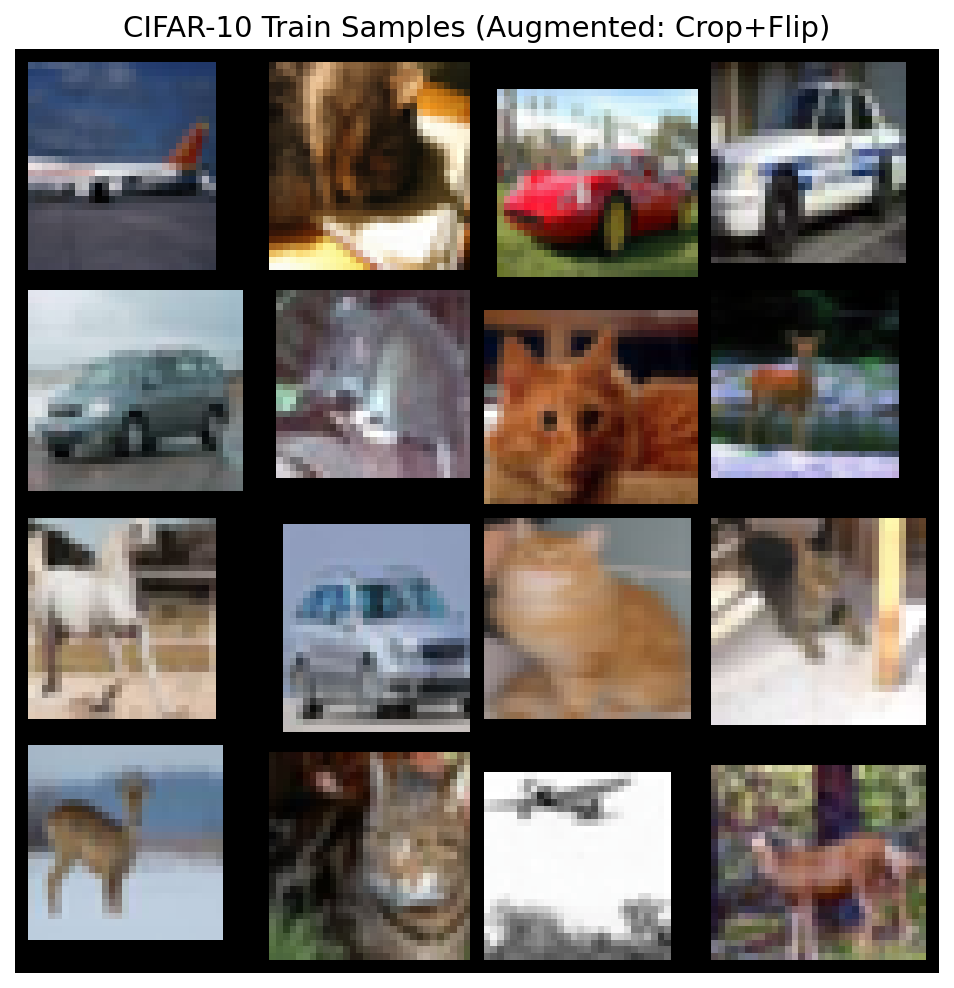

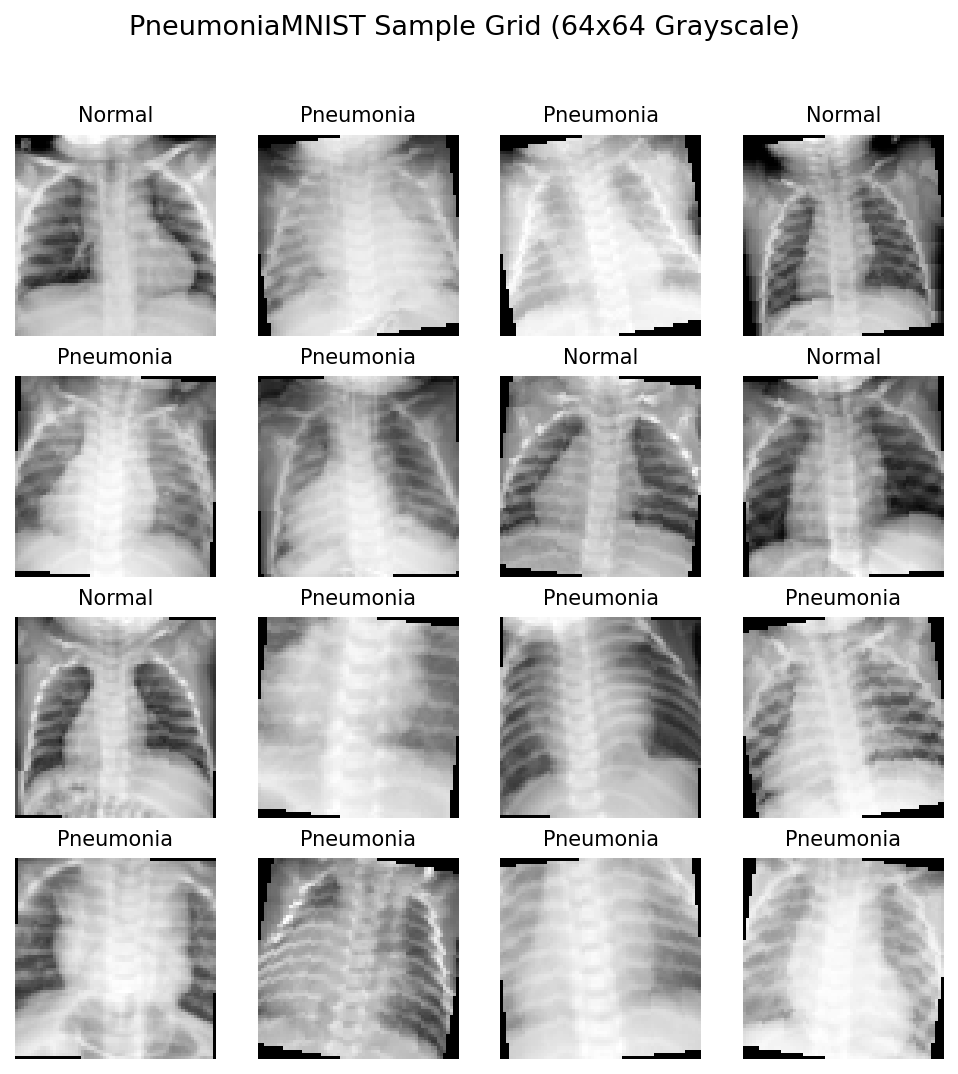

In [2]:
import os
from PIL import Image
from IPython.display import display

from src.data.cifar import get_cifar10_dataloaders, plot_cifar_sample_grid
from src.data.pneumonia import get_pneumonia_dataloaders, plot_pneumonia_sample_grid

# 1. Load CIFAR-10 DataLoaders
# Tip: Use smoke=False for the full 45k/5k/10k dataset, or smoke=True for a rapid offline check
cifar_train, cifar_val, cifar_test, cifar_meta = get_cifar10_dataloaders(batch_size=64, smoke=False)
plot_cifar_sample_grid(cifar_train, save_path="results/cifar_sample_grid.png")

# 2. Load PneumoniaMNIST DataLoaders (size=64)
pneumo_train, pneumo_val, pneumo_test, pneumo_meta = get_pneumonia_dataloaders(batch_size=64, size=64, smoke=False)
plot_pneumonia_sample_grid(pneumo_train, save_path="results/pneumonia_sample_grid.png")

# Display sample grids
if os.path.exists("results/cifar_sample_grid.png"):
    display(Image.open("results/cifar_sample_grid.png"))
if os.path.exists("results/pneumonia_sample_grid.png"):
    display(Image.open("results/pneumonia_sample_grid.png"))

## Section 2: Architecture Verification, Analytical Parameter Formulas & Shape Progression
- Hand formula verification: $\text{BN} = 2 \cdot C_{in}$, $\text{Conv3x3} = 9 \cdot C_{in} \cdot k$.
- Proving Block 1 Layer 1 ($C_{in}=16, k=12$) equals **exactly 1,760 parameters**.
- Verifying DenseNet-40 matches $\sim 1.02\text{M}$ and DenseNet-BC-100 matches $\sim 0.77\text{M}$.
- Verifying custom DenseNet-121 matches `torchvision.models.densenet121` parameter-for-parameter (7,978,856 params).

In [3]:
import os
from src.utils.param_count import (
    verify_block1_layer1_params,
    verify_densenet40_params,
    verify_densenet_bc_100_params,
    compare_with_torchvision_densenet121,
    print_torchinfo_summary
)
from src.utils.shape_checks import generate_densenet40_shape_table
from src.models.densenet import densenet40_cifar

# 1. Run exact analytical parameter proofs
verify_block1_layer1_params()
verify_densenet40_params()
verify_densenet_bc_100_params()
compare_with_torchvision_densenet121()

# 2. Generate and display layer-by-layer shape table for DenseNet-40
shape_table_path = "results/shape_table.md"
generate_densenet40_shape_table(save_path=shape_table_path)
if os.path.exists(shape_table_path):
    with open(shape_table_path, "r", encoding="utf-8") as f:
        lines = f.readlines()[:25]
        print("".join(lines) + "\n... [See results/shape_table.md for all 47 layers]")

# 3. Print torchinfo summary table
model = densenet40_cifar()
print_torchinfo_summary(model, input_size=(1, 3, 32, 32))

[Verification] Block 1, Layer 1 of DenseNet-40 (C_in=16, k=12):
  - Hand Formula:    1,760 parameters
  - sum(p.numel()):  1,760 parameters
  - Match:           PASSED (Exact match: 1,760)

[Verification] DenseNet-40 (k=12, CIFAR-10):
  - Hand Formula:    1,019,722 parameters
  - sum(p.numel()):  1,019,722 parameters (~1.02M)
  - Match:           PASSED

[Verification] DenseNet-BC-100 (k=12, theta=0.5, CIFAR-10):
  - Hand Formula:    769,162 parameters
  - sum(p.numel()):  769,162 parameters (~0.77M)
  - Match:           PASSED

[Comparison] Custom DenseNet-121 vs Torchvision DenseNet-121:
  - Custom Hand Count:     7,978,856
  - Custom Runtime Count:  7,978,856
  - Torchvision Runtime:   7,978,856
  - Difference:            0
  - Exact Match:           True

[Shape Checks] Shape table written to results/shape_table.md (47 entries)
# DenseNet-40 Layer-by-Layer Tensor Shape Table

Input: `1 x 3 x 32 x 32` (CIFAR-10 image)
Configuration: `growth_rate k = 12`, `layers_per_block = (12, 12,

## Section 3: Optimization Sanity Checks
1. **Initial Loss Check:** Confirms loss $\approx \ln(C) = \ln(10) \approx 2.3026$ for an untrained network on CIFAR-10.
2. **Gradient Flow Check:** Confirms non-zero gradients across 100% of trainable weight tensors.
3. **Single-Batch Overfitting:** Overfits a single mini-batch within 60 steps to ensure optimization capacity.

In [4]:
from src.train.sanity import run_sanity_checks
from src.train.engine import get_device

# Identify the available device (GPU or CPU)
device = get_device()

# Move model and data to the same device
model = model.to(device)
sample_x, sample_y = next(iter(cifar_train))
sample_x = sample_x.to(device)
sample_y = sample_y.to(device)

sanity_results = run_sanity_checks(model, sample_x, sample_y, num_classes=10)

[Device] Using GPU: Tesla T4 with AMP enabled
RUNNING ARCHITECTURAL & OPTIMIZATION SANITY CHECKS
[Sanity Check 1: Initial Loss] Classes C=10:
  - Theoretical ln(C): 2.3026
  - Observed Loss:     2.3040 (diff: 0.0015, tol: 0.5)
  - Status:            PASSED

[Sanity Check 2: Gradient Flow] Total trainable tensors: 119
  - Zero-gradient tensors: NONE (All parameters receive active gradients)
  - Status:                PASSED

[Sanity Check 3: Overfit One Batch] (60 Adam steps, batch_size=32):
  - Initial Loss:  2.2887
  - Final Loss:    0.0001 (target < 0.15)
  - Final Acc:     100.0%
  - Status:        PASSED

SANITY CHECKS RESULT: ALL PASSED



## Section 4: Learning Rate Range Test
- Exponential learning rate sweep from $10^{-6}$ to $2.0$ over 100 steps.
- Identifies point of steepest descent to validate base learning rate choice.

[Device] Using GPU: Tesla T4 with AMP enabled

[LR Range Test] Sweeping LR from 1.0e-06 to 2.0e+00 over 100 steps...
[LR Range Test] Minimum Loss: 3.6613
[LR Range Test] Suggested LR (steepest descent): 6.0342e-03 (0.00603)
[LR Range Test] Plot saved to results/lr_range_test.png


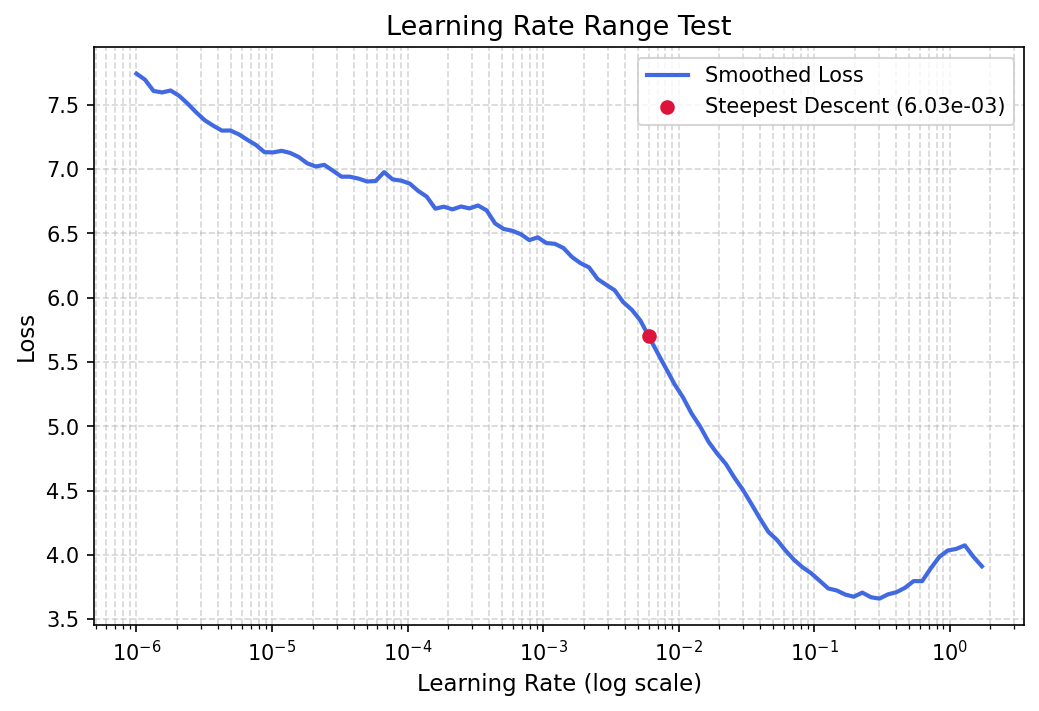

In [5]:
import os
from PIL import Image
from IPython.display import display
import torch.nn as nn
from src.train.lr_range_test import run_lr_range_test
from src.train.engine import get_device

device = get_device()
criterion = nn.CrossEntropyLoss()
lrs, losses, suggested_lr = run_lr_range_test(
    model=model.to(device),
    dataloader=cifar_train,
    criterion=criterion,
    device=device,
    min_lr=1e-6,
    max_lr=2.0,
    num_iter=100,
    save_path="results/lr_range_test.png"
)

if os.path.exists("results/lr_range_test.png"):
    display(Image.open("results/lr_range_test.png"))

## Section 5: CIFAR-10+ Reproduction Benchmark
Trains and compares:
1. **DenseNet-40 ($k=12$)** (Paper error: 5.24%)
2. **DenseNet-BC-100 ($k=12$)** (Paper error: 4.51%)
3. **ResNet-56** (Paper baseline error: ~6.97%)

*Note:* On Colab GPU, set `--epochs 300` for full reproduction (~2.5 hours under AMP). Set `--smoke` for a fast 1-minute test.

[Seed] Deterministic seed set to 42
[Device] Using GPU: Tesla T4 with AMP enabled

STARTING CIFAR-10 REPRODUCTION: DENSENET40
[densenet40] Total Trainable Parameters: 1,019,722

[Training] Starting experiment 'cifar10_densenet40_smoke' for 2 epochs on CUDA...
Epoch 001/002 | Train Loss: 2.3607 | Val Loss: 14.7198 | Val accuracy: 0.1406 (*BEST*) | Time: 1.6s
Epoch 002/002 | Train Loss: 2.2669 | Val Loss: 3.8128 | Val accuracy: 0.1406  | Time: 0.3s
[Training] Epoch log written to results/cifar10_densenet40_smoke_history.csv
[Curves] Training plots written to results/cifar10_densenet40_smoke_curves.png
[Training] Completed in 0.05 minutes. Best accuracy: 0.1406

[densenet40] Final Test Evaluation:
  - Test Accuracy: 14.06%
  - Test Top-1 Error: 85.94%


REPRODUCTION SUMMARY TABLE (CIFAR-10+)
Model                | Parameters   | Test Acc (%)   | Test Error (%)
------------------------------------------------------------
densenet40           | 1,019,722    | 14.06          | 85.94         

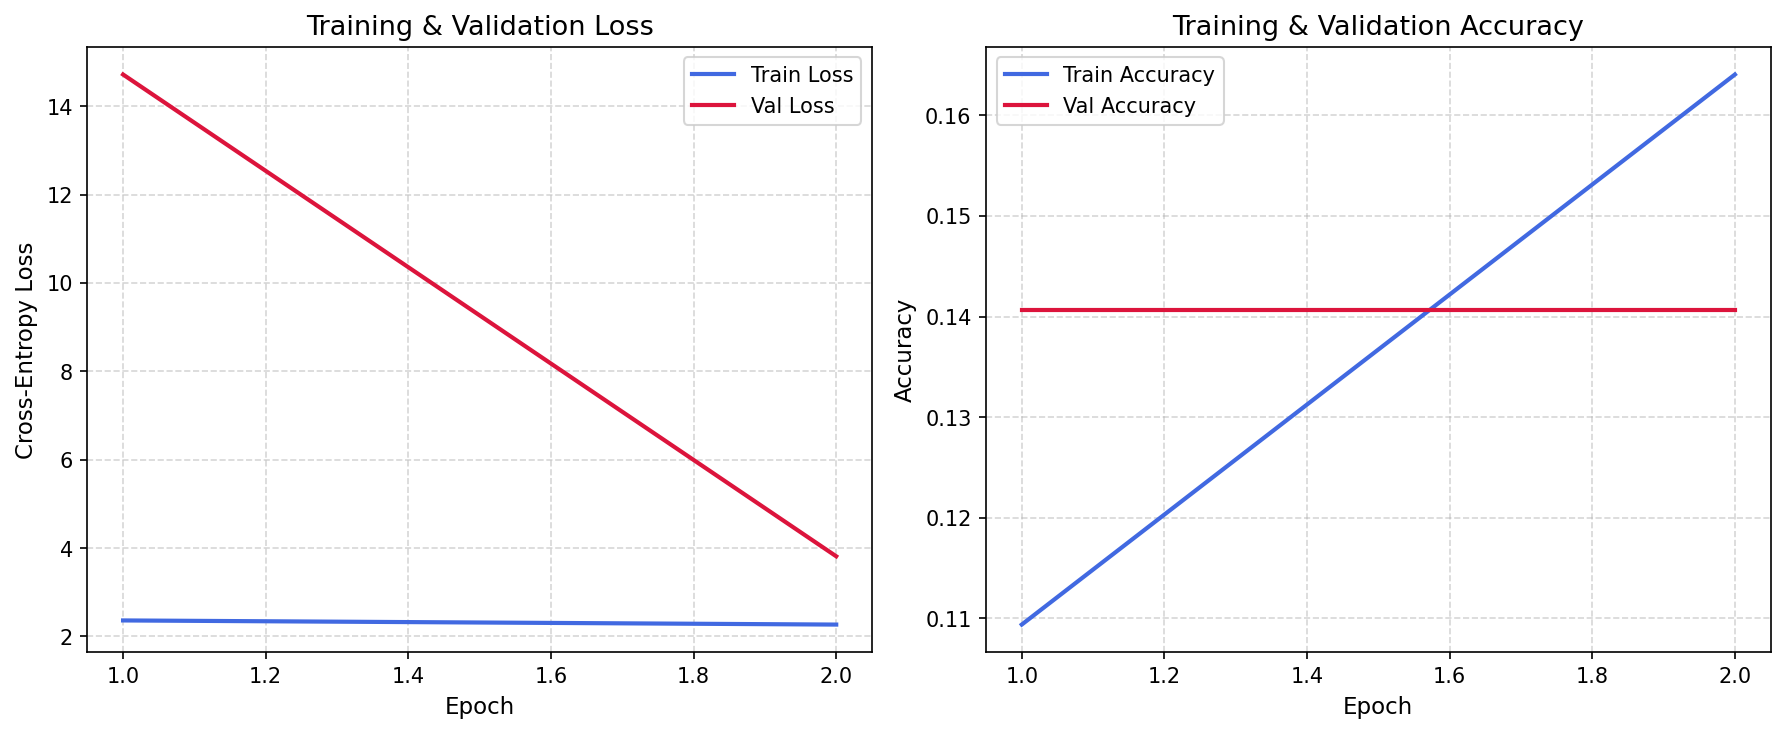

In [6]:
import os
from PIL import Image
from IPython.display import display

# Execute CIFAR-10 reproduction (change --smoke to --epochs 300 for the full Colab paper run)
!python -m experiments.reproduce_cifar --model densenet40 --smoke --batch-size 64 --lr 0.1

# Display training curves
for curve_file in [
    "results/cifar10_densenet40_300ep_curves.png",
    "results/cifar10_densenet40_50ep_curves.png",
    "results/cifar10_densenet40_smoke_curves.png",
]:
    if os.path.exists(curve_file):
        display(Image.open(curve_file))
        break

## Section 6: Medical Transfer Extension on PneumoniaMNIST (size=64)
Evaluates:
1. **Simple CNN** (5-layer baseline adapted from MedMNIST notebook)
2. **Custom DenseNet** (DenseNet-BC adapted for 1-channel 64x64)
3. **Fine-Tuned DenseNet-121** (Torchvision ImageNet pretrained)
- Class imbalance handled via class-weighted CrossEntropyLoss.

[Seed] Deterministic seed set to 42
[Device] Using GPU: Tesla T4 with AMP enabled
[Pneumonia Data] Note: Initializing synthetic data (name 'Subset' is not defined).
[Pneumonia Data] Class counts: {np.int64(0): np.int64(31), np.int64(1): np.int64(97)}, Computed Loss Weights: [2.064516067504883, 0.6597937941551208]
[Pneumonia Data] Batch Shape: torch.Size([64, 1, 64, 64]), Dtype: torch.float32
[Pneumonia Data] Targets Shape: torch.Size([64]), Dtype: torch.int64
[Pneumonia Data] Splits -> Train: 128, Val: 64, Test: 64

RUNNING PNEUMONIAMNIST EXPERIMENT: CUSTOM_DENSENET (size=64)
[custom_densenet] Parameters: 174,626

[Training] Starting experiment 'pneumonia_custom_densenet_64_smoke' for 2 epochs on CUDA...
Epoch 001/002 | Train Loss: 0.6939 | Val Loss: 0.6905 | Val auc: 0.5661 (*BEST*) | Time: 1.1s
Epoch 002/002 | Train Loss: 0.6935 | Val Loss: 0.6944 | Val auc: 0.5789 (*BEST*) | Time: 0.3s
[Training] Epoch log written to results/pneumonia_custom_densenet_64_smoke_history.csv
[Curves] Tr

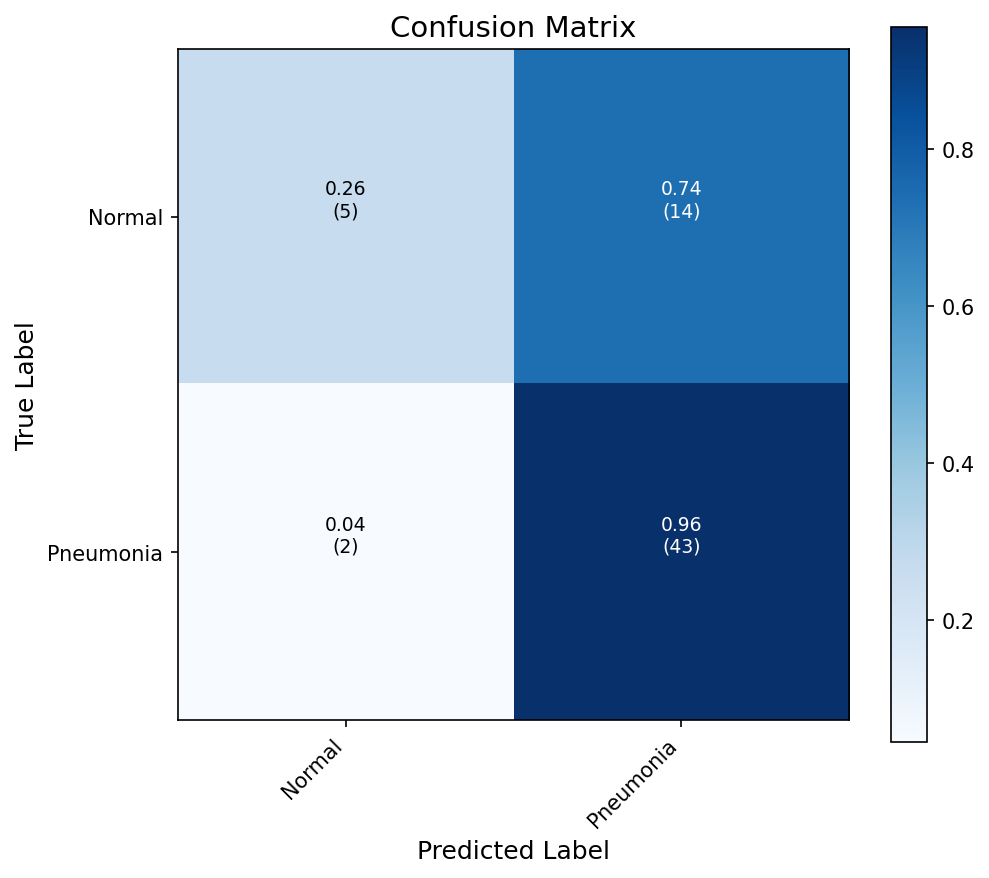

Artifact: pneumonia_custom_densenet_64_smoke_curves.png


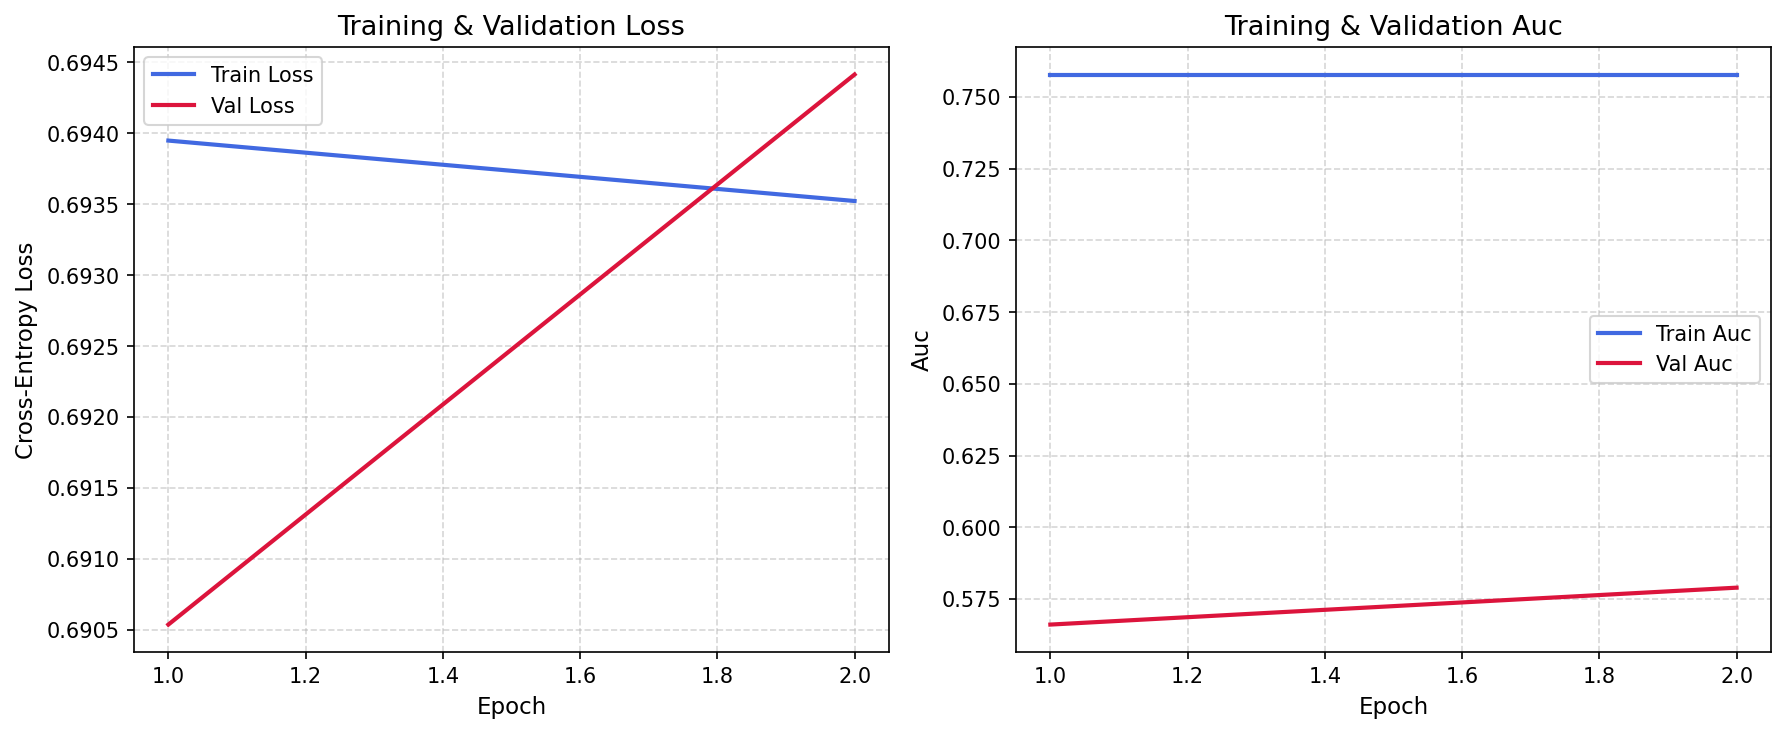

Artifact: pneumonia_custom_densenet_64_smoke_reliability.png


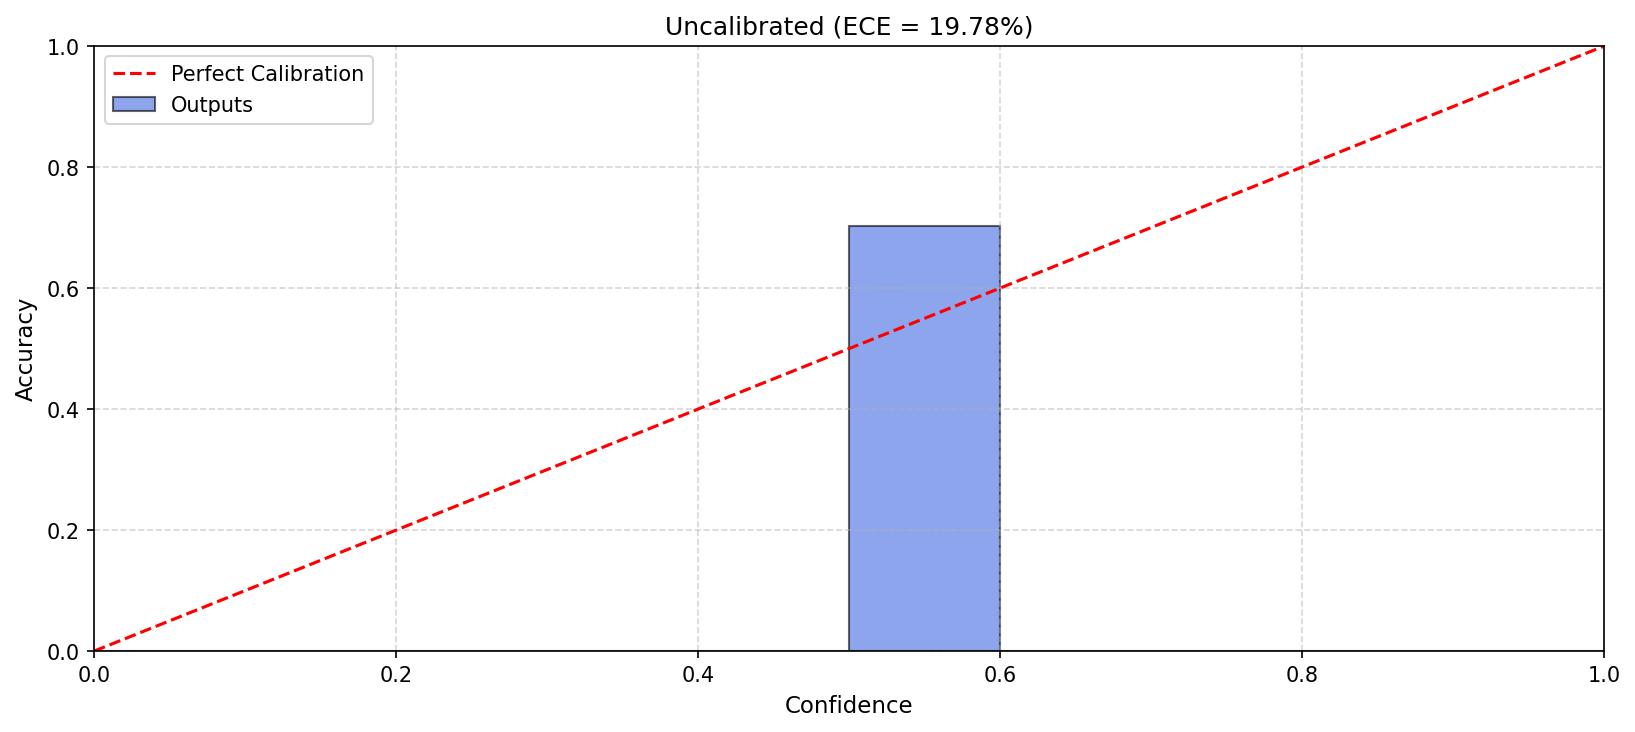

Artifact: pneumonia_custom_densenet_64_smoke_tradeoff.png


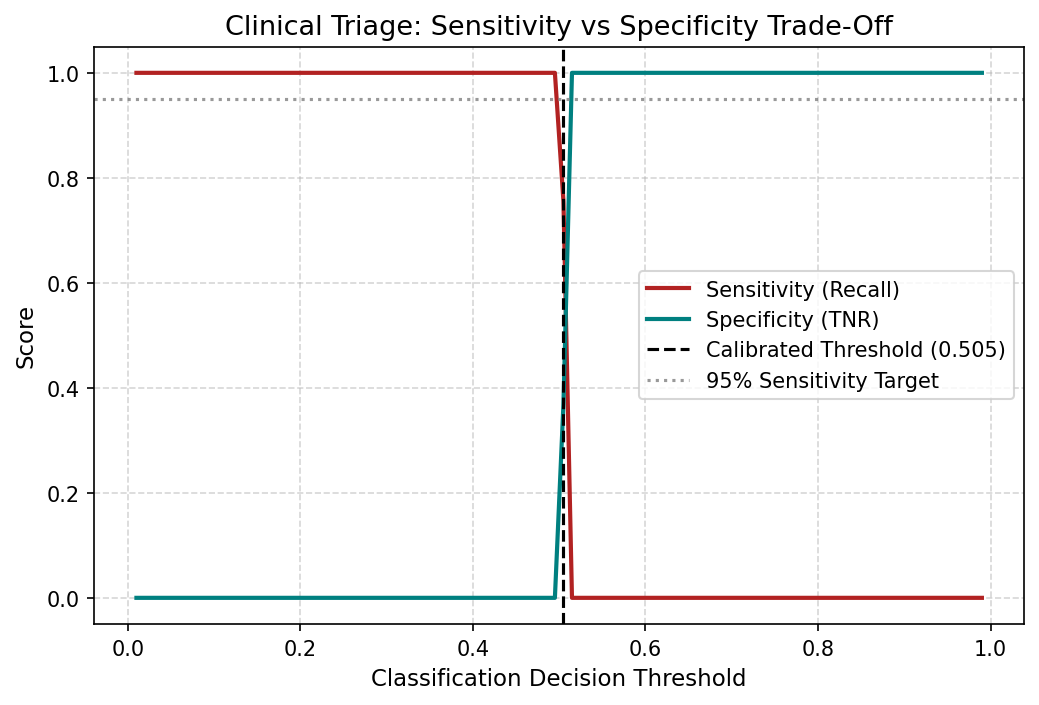

Artifact: pneumonia_sample_grid.png


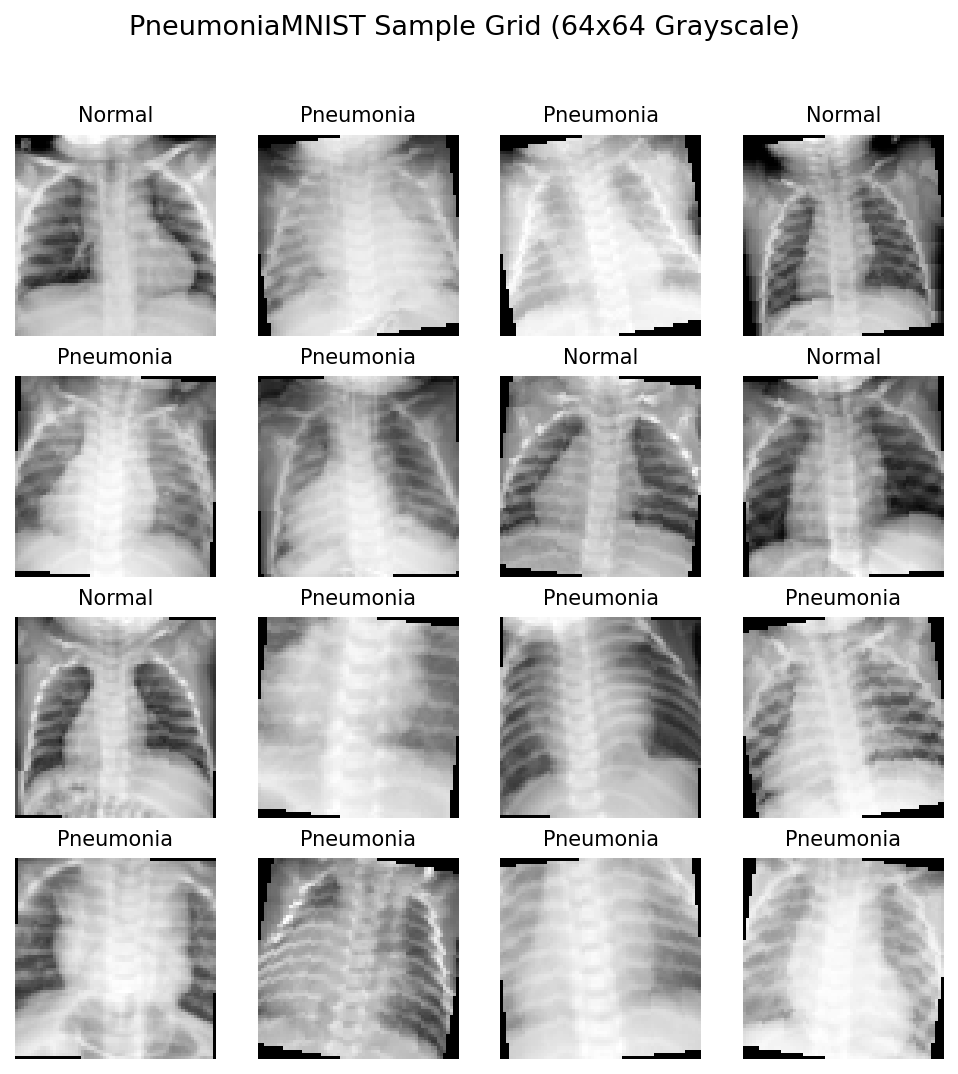

In [7]:
import os
from PIL import Image
from IPython.display import display

# Execute PneumoniaMNIST benchmark (change --smoke to --epochs 40 for full GPU training)
!python -m experiments.run_pneumonia --model custom_densenet --size 64 --smoke

# Display calibration and evaluation figures
if os.path.exists("results"):
    for fig_name in sorted(os.listdir("results")):
        if fig_name.startswith("pneumonia_") and fig_name.endswith(".png"):
            print(f"Artifact: {fig_name}")
            display(Image.open(os.path.join("results", fig_name)))

## Section 7: Systematic Ablation Studies (One-Factor-At-A-Time)
Evaluates each factor from the fixed baseline (`configs/baseline.yaml`):
- Growth rate $k \in \{8, 12, 24\}$
- Bottleneck on vs off
- Compression $\theta \in \{0.5, 1.0\}$
- Input resolution ($28, 64, 128$)
- Dropout $p \in \{0.0, 0.2\}$

[Device] Using GPU: Tesla T4 with AMP enabled

--- Running Ablation 1: Growth Rate k in {8, 12, 24} ---
[Seed] Deterministic seed set to 42

[Training] Starting experiment 'ablation_growth_rate_8' for 2 epochs on CUDA...
Epoch 001/002 | Train Loss: 2.3065 | Val Loss: 2.8525 | Val accuracy: 0.0938 (*BEST*) | Time: 1.1s
Epoch 002/002 | Train Loss: 2.2512 | Val Loss: 2.4013 | Val accuracy: 0.0938  | Time: 0.1s
[Training] Epoch log written to results/ablation_growth_rate_8_history.csv
[Curves] Training plots written to results/ablation_growth_rate_8_curves.png
[Training] Completed in 0.03 minutes. Best accuracy: 0.0938
[Seed] Deterministic seed set to 42

[Training] Starting experiment 'ablation_growth_rate_12' for 2 epochs on CUDA...
Epoch 001/002 | Train Loss: 2.3040 | Val Loss: 3.9757 | Val accuracy: 0.0938 (*BEST*) | Time: 0.4s
Epoch 002/002 | Train Loss: 2.2319 | Val Loss: 2.4845 | Val accuracy: 0.0938  | Time: 0.2s
[Training] Epoch log written to results/ablation_growth_rate_12_histo

,factor,value,dataset,params,val_metric,test_metric,epochs,seed,train_time
0,growth_rate,8,CIFAR-10,79850,7.81,7.81,2,42,15.9
1,growth_rate,12,CIFAR-10,176122,7.81,7.81,2,42,15.0
2,growth_rate,24,CIFAR-10,690346,7.81,7.81,2,42,28.4
3,growth_rate,8,CIFAR-10,79850,9.38,10.94,2,42,1.9
4,growth_rate,12,CIFAR-10,176122,9.38,10.94,2,42,1.1
5,growth_rate,24,CIFAR-10,690346,18.75,15.62,2,42,1.3


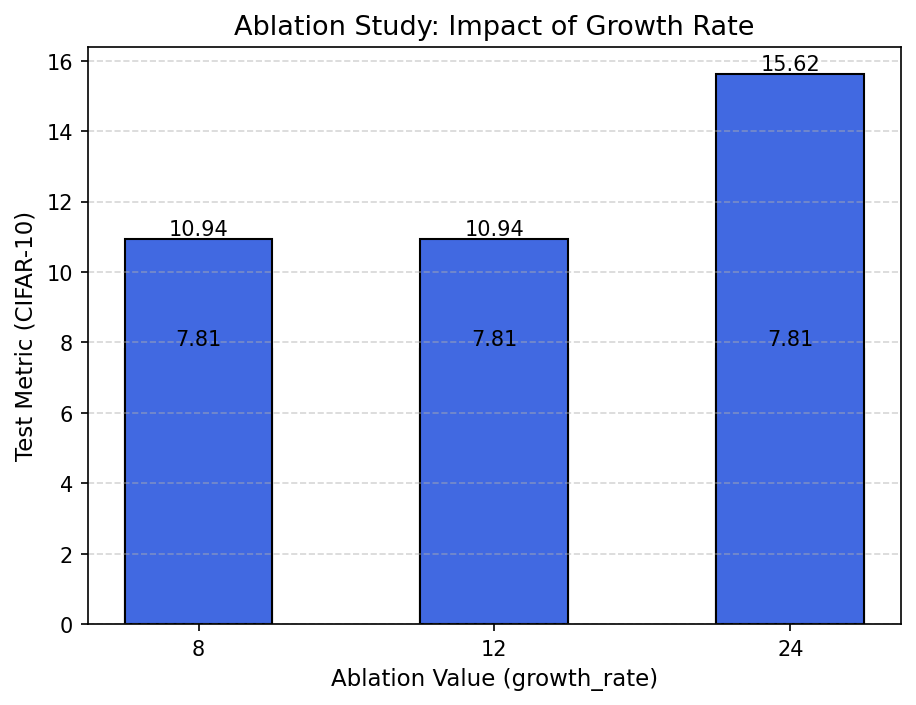

In [8]:
import os
import pandas as pd
from PIL import Image
from IPython.display import display

# Run ablation suite (change --smoke to --epochs 20 for full Colab exploration)
!python -m experiments.run_ablations --factor growth_rate --smoke

csv_path = "results/ablations.csv"
if os.path.exists(csv_path):
    df_ablations = pd.read_csv(csv_path)
    display(df_ablations)

# Display ablation factor plots
for f in ["growth_rate", "bottleneck", "compression", "resolution", "dropout"]:
    p = f"results/ablation_{f}.png"
    if os.path.exists(p):
        display(Image.open(p))

## Section 8: Diagnostic Error Analysis & Misclassifications
- Detailed confusion matrix and per-class error breakdown.
- Visual inspection grid of misclassified test samples with model confidence.

[Error Analysis] Misclassified grid saved to results/misclassified_grid.png


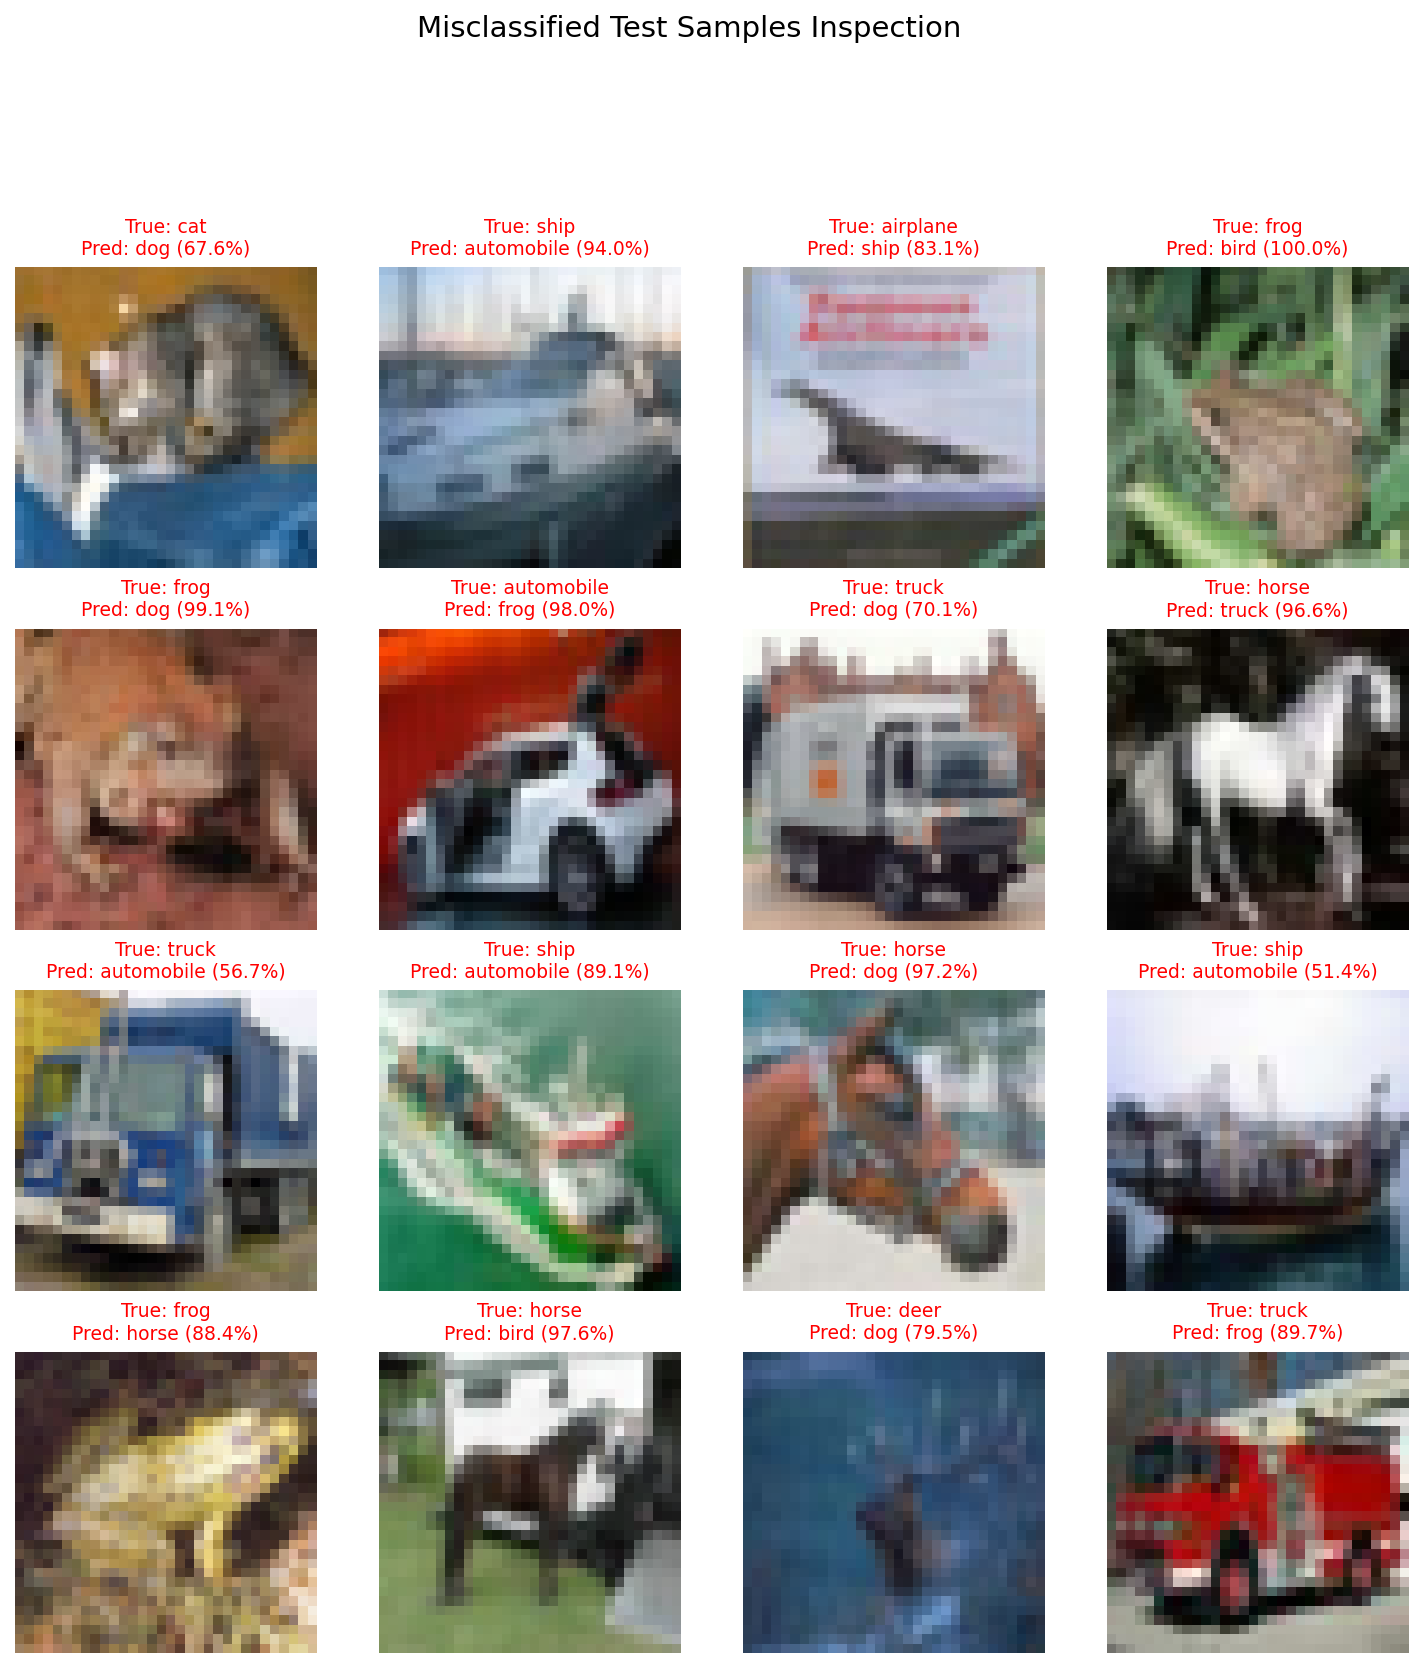

In [9]:
import os
from PIL import Image
from IPython.display import display
from src.eval.error_analysis import analyze_misclassifications, plot_misclassified_grid

misclass_data = analyze_misclassifications(
    model=model.to(device),
    dataloader=cifar_test,
    device=device,
    class_names=cifar_meta["classes"],
    max_samples=16
)
plot_misclassified_grid(
    misclass_data,
    class_names=cifar_meta["classes"],
    mean=cifar_meta["mean"],
    std=cifar_meta["std"],
    save_path="results/misclassified_grid.png"
)
if os.path.exists("results/misclassified_grid.png"):
    display(Image.open("results/misclassified_grid.png"))

## Section 9: Clinical Calibration & Threshold Tuning
- Selecting threshold on validation set for $\ge 95\%$ sensitivity.
- Reliability diagram and Expected Calibration Error (ECE).
- Post-hoc temperature scaling.

Artifact: pneumonia_custom_densenet_64_smoke_reliability.png


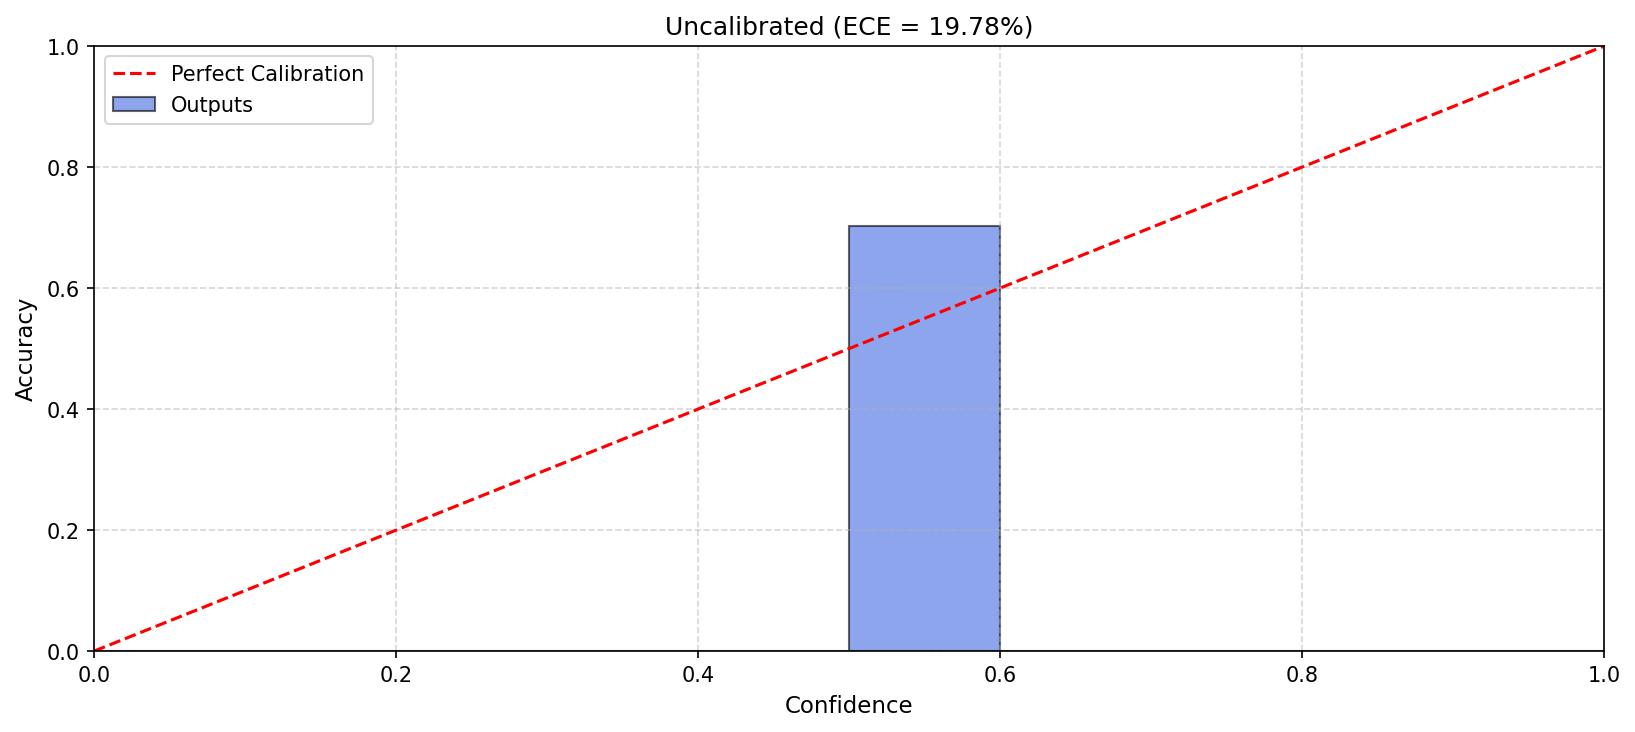

Artifact: pneumonia_custom_densenet_64_smoke_tradeoff.png


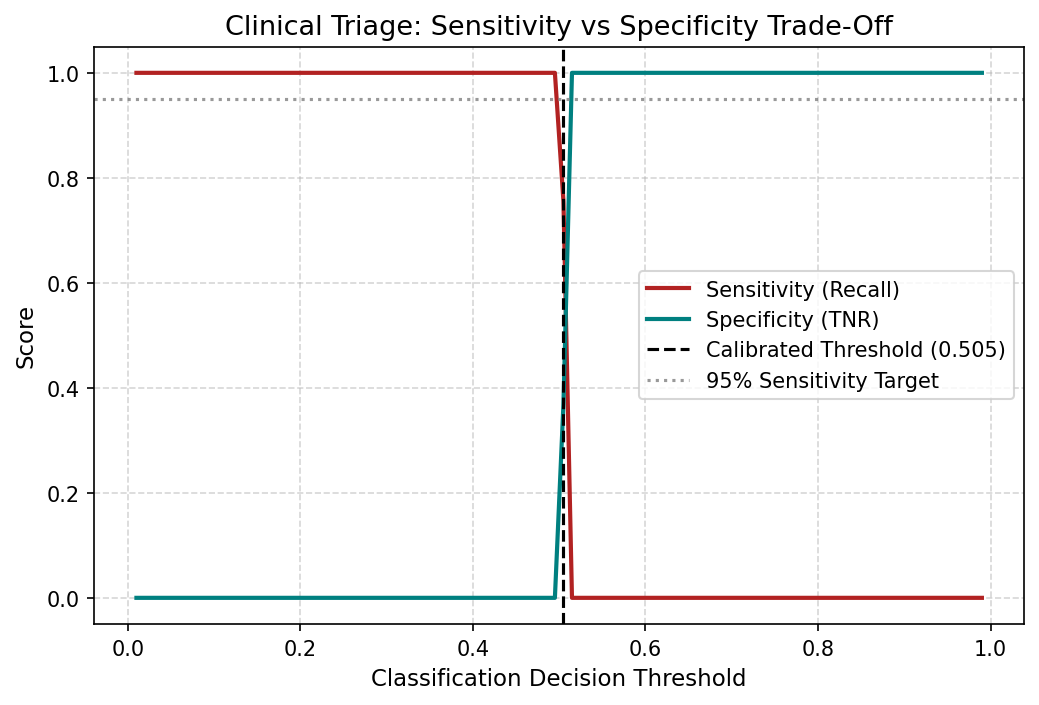

Artifact: pneumonia_custom_densenet_64_smoke_cm.png


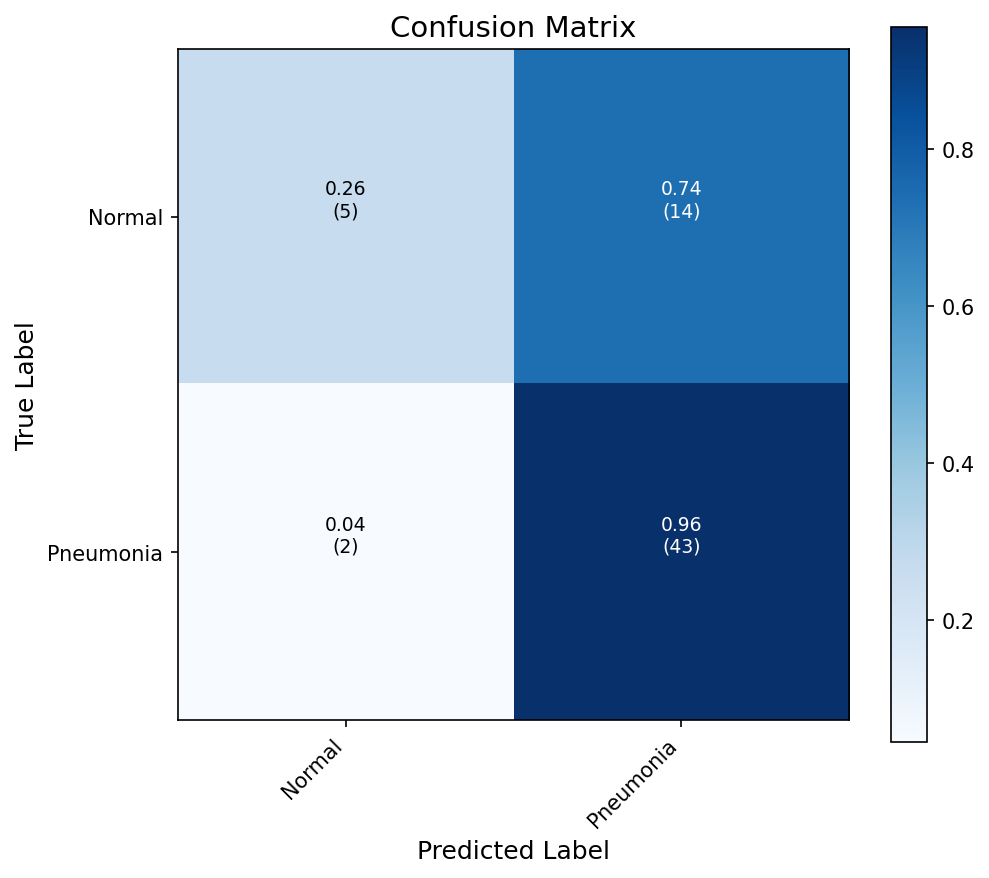

In [10]:
import os
from PIL import Image
from IPython.display import display

# Display calibration artifacts generated during PneumoniaMNIST experiments
if os.path.exists("results"):
    for f in ["reliability.png", "tradeoff.png", "cm.png"]:
        for fname in sorted(os.listdir("results")):
            if f in fname:
                print(f"Artifact: {fname}")
                display(Image.open(os.path.join("results", fname)))

## Section 10: Interactive Gradio Diagnostic Explorer Launch
- Launches interactive diagnostic explorer with `share=True` for a public Colab URL.
- Features: Dataset selector, Sensitivity slider, and Figure 5 Feature-Reuse Heatmap / Grad-CAM.

In [11]:
from app.gradio_demo import build_app

demo_app = build_app()
# Launch with share=True to obtain a public URL on Google Colab
demo_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7c71cc746a72bd8b00.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
